In [ ]:
import pandas as pd

In [ ]:
import numpy as np

In [ ]:
import pandas as pd
import numpy as np

In [ ]:


print(pd.__version__)
print(np.__version__)

In [48]:
import pandas as pd
import numpy as np

np.random.seed(42)

print("Environment is ready!")

Environment is ready!


In [49]:
customers = [f"C{str(i).zfill(4)}" for i in range(1, 61)]

branches = [
    "Karachi",
    "Sukkur",
    "Lahore",
    "Islamabad",
    "Hyderabad"
]

account_types = [
    "Savings",
    "Current"
]

transaction_types = [
    "Deposit",
    "Withdrawal",
    "Transfer"
]

print(customers[:5])
print(branches)
print(account_types)
print(transaction_types)

['C0001', 'C0002', 'C0003', 'C0004', 'C0005']
['Karachi', 'Sukkur', 'Lahore', 'Islamabad', 'Hyderabad']
['Savings', 'Current']
['Deposit', 'Withdrawal', 'Transfer']


In [50]:
n = 250

transaction_ids = [
    f"T{str(i).zfill(5)}"
    for i in range(1, n + 1)
]

customer_ids = np.random.choice(customers, n)

transaction_type = np.random.choice(
    transaction_types,
    n
)

branch = np.random.choice(
    branches,
    n
)

account_type = np.random.choice(
    account_types,
    n
)

print(transaction_ids[:5])
print(customer_ids[:5])
print(transaction_type[:5])

['T00001', 'T00002', 'T00003', 'T00004', 'T00005']
['C0039' 'C0052' 'C0029' 'C0015' 'C0043']
['Deposit' 'Withdrawal' 'Deposit' 'Withdrawal' 'Withdrawal']


In [51]:
dates = pd.date_range(
    start="2025-01-01",
    end="2025-12-31"
)

transaction_dates = np.random.choice(dates, n)

print(transaction_dates[:5])

['2025-01-28T00:00:00.000000' '2025-03-19T00:00:00.000000'
 '2025-08-04T00:00:00.000000' '2025-12-31T00:00:00.000000'
 '2025-06-03T00:00:00.000000']


In [52]:
amounts = np.random.randint(
    500,
    250001,
    n
)

print(amounts[:10])

[ 73819 126385 110277  17868 146900 188514  92251 230703  27806 217023]


In [53]:
df = pd.DataFrame({
    "TransactionID": transaction_ids,
    "CustomerID": customer_ids,
    "Date": transaction_dates,
    "Branch": branch,
    "AccountType": account_type,
    "TransactionType": transaction_type,
    "Amount": amounts
})

In [54]:
df.head()

,TransactionID,CustomerID,Date,Branch,AccountType,TransactionType,Amount
0,T00001,C0039,2025-01-28,Islamabad,Current,Deposit,73819
1,T00002,C0052,2025-03-19,Hyderabad,Savings,Withdrawal,126385
2,T00003,C0029,2025-08-04,Karachi,Current,Deposit,110277
3,T00004,C0015,2025-12-31,Sukkur,Savings,Withdrawal,17868
4,T00005,C0043,2025-06-03,Sukkur,Savings,Withdrawal,146900


In [55]:
df.shape

(250, 7)

In [56]:
df.to_csv("../data/banking_transactions.csv", index=False)

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   TransactionID    250 non-null    str           
 1   CustomerID       250 non-null    str           
 2   Date             250 non-null    datetime64[us]
 3   Branch           250 non-null    str           
 4   AccountType      250 non-null    str           
 5   TransactionType  250 non-null    str           
 6   Amount           250 non-null    int32         
dtypes: datetime64[us](1), int32(1), str(5)
memory usage: 12.8 KB


In [58]:
df["Amount"].describe()

count       250.000000
mean     128509.480000
std       71169.926086
min         626.000000
25%       67150.000000
50%      130610.500000
75%      186250.000000
max      249767.000000
Name: Amount, dtype: float64

In [59]:
df["Amount"].sum()

np.int64(32127370)

In [60]:
df.groupby("TransactionType")["Amount"].sum()

TransactionType
Deposit        9862594
Transfer      10968252
Withdrawal    11296524
Name: Amount, dtype: int32

In [61]:
df.groupby("Branch")["Amount"].sum()

Branch
Hyderabad    7921475
Islamabad    7428763
Karachi      6194186
Lahore       4029844
Sukkur       6553102
Name: Amount, dtype: int32

In [62]:
df.groupby("AccountType")["Amount"].sum()

AccountType
Current    14059558
Savings    18067812
Name: Amount, dtype: int32

In [63]:
df.groupby(df["Date"].dt.month)["Amount"].sum()

Date
1     3675849
2     2112262
3     2673987
4     3414954
5     3092158
6     1915751
7     1329358
8     3087103
9     1520200
10    3177499
11    4003414
12    2124835
Name: Amount, dtype: int32

In [64]:
df.groupby("CustomerID")["Amount"].sum().sort_values(ascending=False).head(10)

CustomerID
C0039    1322677
C0044    1208828
C0024    1171110
C0015    1041383
C0027    1012050
C0028     979863
C0026     960765
C0060     948171
C0008     829683
C0051     819600
Name: Amount, dtype: int32

In [65]:
df[df["Amount"] > 200000]

,TransactionID,CustomerID,Date,Branch,AccountType,TransactionType,Amount
7,T00008,C0039,2025-11-08,Karachi,Savings,Transfer,230703
9,T00010,C0019,2025-01-03,Hyderabad,Savings,Deposit,217023
12,T00013,C0011,2025-12-29,Hyderabad,Savings,Transfer,212451
13,T00014,C0024,2025-08-27,Hyderabad,Savings,Deposit,243511
21,T00022,C0002,2025-07-21,Islamabad,Savings,Transfer,238671
25,T00026,C0038,2025-03-27,Hyderabad,Current,Withdrawal,217638
26,T00027,C0002,2025-05-06,Islamabad,Current,Withdrawal,237072
28,T00029,C0021,2025-01-25,Sukkur,Current,Transfer,200476
36,T00037,C0027,2025-04-19,Islamabad,Savings,Withdrawal,233293
42,T00043,C0015,2025-04-21,Sukkur,Savings,Transfer,232948


In [66]:
df["TransactionType"].value_counts()

TransactionType
Withdrawal    86
Deposit       82
Transfer      82
Name: count, dtype: int64

In [67]:
df.groupby("Branch")["Amount"].mean().sort_values(ascending=False)

Branch
Sukkur       136522.958333
Islamabad    135068.418182
Hyderabad    129860.245902
Karachi      126411.959184
Lahore       108914.702703
Name: Amount, dtype: float64

In [68]:
df.groupby(["Branch", "TransactionType"])["Amount"].sum()

Branch     TransactionType
Hyderabad  Deposit            1978472
           Transfer           2554743
           Withdrawal         3388260
Islamabad  Deposit            2340722
           Transfer           2681014
           Withdrawal         2407027
Karachi    Deposit            2176528
           Transfer           1614301
           Withdrawal         2403357
Lahore     Deposit            1957744
           Transfer           1125269
           Withdrawal          946831
Sukkur     Deposit            1409128
           Transfer           2992925
           Withdrawal         2151049
Name: Amount, dtype: int32

In [69]:
df.groupby("AccountType")["Amount"].mean()

AccountType
Current    124420.867257
Savings    131881.839416
Name: Amount, dtype: float64

In [70]:
df["Date"].dt.month_name().value_counts().sort_index()

Date
April        24
August       25
December     17
February     15
January      29
July         12
June         18
March        21
May          24
November     28
October      25
September    12
Name: count, dtype: int64

In [71]:
import matplotlib.pyplot as plt

In [72]:
import matplotlib.pyplot as plt

<Axes: xlabel='Branch'>

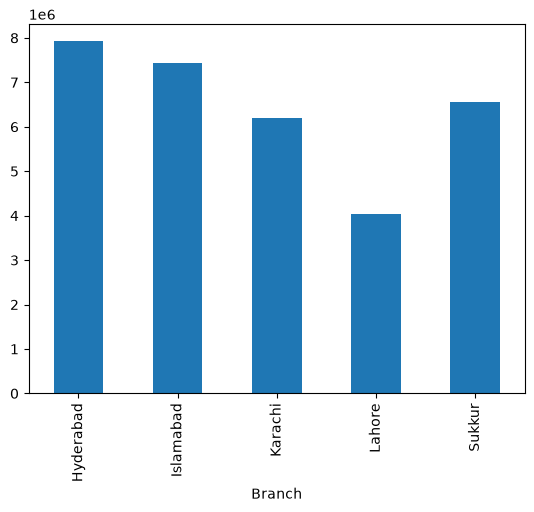

In [73]:
df.groupby("Branch")["Amount"].sum().plot(kind="bar")

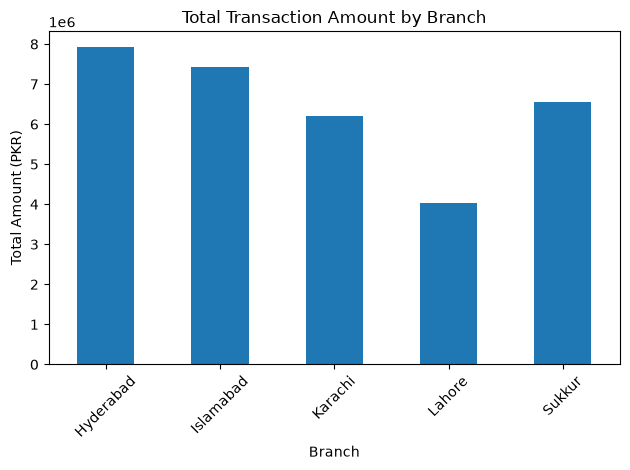

In [74]:
import matplotlib.pyplot as plt

branch_total = df.groupby("Branch")["Amount"].sum()

branch_total.plot(kind="bar")

plt.title("Total Transaction Amount by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Amount (PKR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [75]:
branch_total = df.groupby("Branch")["Amount"].sum()

In [76]:
branch_total = df.groupby("Branch")["Amount"].sum()

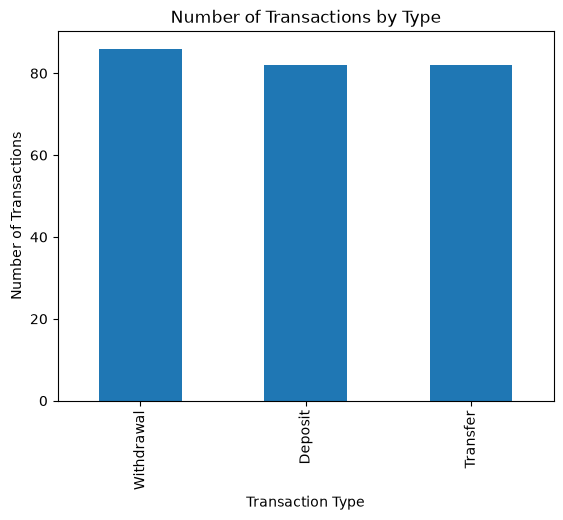

In [77]:
transaction_counts = df["TransactionType"].value_counts()

transaction_counts.plot(kind="bar")

plt.title("Number of Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

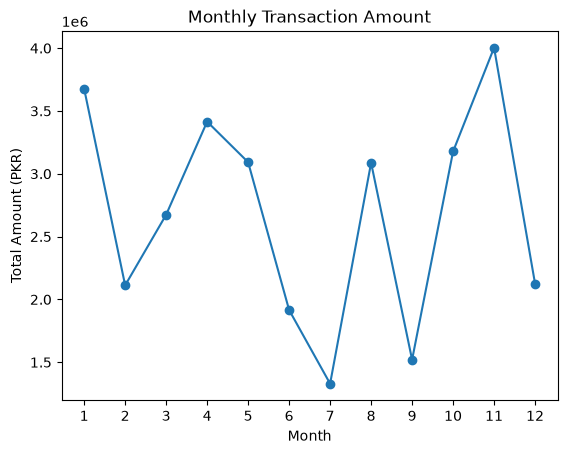

In [78]:
monthly_total = df.groupby(df["Date"].dt.month)["Amount"].sum()

monthly_total.plot(kind="line", marker="o")

plt.title("Monthly Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Total Amount (PKR)")
plt.xticks(range(1, 13))

plt.show()

In [79]:
df.groupby("AccountType")["Amount"].sum()

AccountType
Current    14059558
Savings    18067812
Name: Amount, dtype: int32

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [81]:
df.head()

,TransactionID,CustomerID,Date,Branch,AccountType,TransactionType,Amount
0,T00001,C0039,2025-01-28,Islamabad,Current,Deposit,73819
1,T00002,C0052,2025-03-19,Hyderabad,Savings,Withdrawal,126385
2,T00003,C0029,2025-08-04,Karachi,Current,Deposit,110277
3,T00004,C0015,2025-12-31,Sukkur,Savings,Withdrawal,17868
4,T00005,C0043,2025-06-03,Sukkur,Savings,Withdrawal,146900


In [82]:
import pandas as pd

df = pd.read_csv("../data/banking_transactions.csv")

In [83]:
df.head()

,TransactionID,CustomerID,Date,Branch,AccountType,TransactionType,Amount
0,T00001,C0039,2025-01-28,Islamabad,Current,Deposit,73819
1,T00002,C0052,2025-03-19,Hyderabad,Savings,Withdrawal,126385
2,T00003,C0029,2025-08-04,Karachi,Current,Deposit,110277
3,T00004,C0015,2025-12-31,Sukkur,Savings,Withdrawal,17868
4,T00005,C0043,2025-06-03,Sukkur,Savings,Withdrawal,146900


In [84]:
df["Date"] = pd.to_datetime(df["Date"])

In [85]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   TransactionID    250 non-null    str           
 1   CustomerID       250 non-null    str           
 2   Date             250 non-null    datetime64[us]
 3   Branch           250 non-null    str           
 4   AccountType      250 non-null    str           
 5   TransactionType  250 non-null    str           
 6   Amount           250 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(5)
memory usage: 13.8 KB


In [86]:
df.info

<bound method DataFrame.info of     TransactionID CustomerID       Date     Branch AccountType  \
0          T00001      C0039 2025-01-28  Islamabad     Current   
1          T00002      C0052 2025-03-19  Hyderabad     Savings   
2          T00003      C0029 2025-08-04    Karachi     Current   
3          T00004      C0015 2025-12-31     Sukkur     Savings   
4          T00005      C0043 2025-06-03     Sukkur     Savings   
..            ...        ...        ...        ...         ...   
245        T00246      C0054 2025-12-12  Islamabad     Savings   
246        T00247      C0032 2025-10-29  Islamabad     Savings   
247        T00248      C0032 2025-12-29  Hyderabad     Current   
248        T00249      C0024 2025-08-06    Karachi     Current   
249        T00250      C0041 2025-05-21  Islamabad     Current   

    TransactionType  Amount  
0           Deposit   73819  
1        Withdrawal  126385  
2           Deposit  110277  
3        Withdrawal   17868  
4        Withdrawal  1469

In [87]:
df = pd.read_csv("../data/banking_transactions.csv")

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [89]:
df = pd.read_csv("../data/banking_transactions.csv")

In [90]:
df.show


AttributeError: 'DataFrame' object has no attribute 'show'

In [91]:
df.show()

AttributeError: 'DataFrame' object has no attribute 'show'

In [92]:
df.info

<bound method DataFrame.info of     TransactionID CustomerID        Date     Branch AccountType  \
0          T00001      C0039  2025-01-28  Islamabad     Current   
1          T00002      C0052  2025-03-19  Hyderabad     Savings   
2          T00003      C0029  2025-08-04    Karachi     Current   
3          T00004      C0015  2025-12-31     Sukkur     Savings   
4          T00005      C0043  2025-06-03     Sukkur     Savings   
..            ...        ...         ...        ...         ...   
245        T00246      C0054  2025-12-12  Islamabad     Savings   
246        T00247      C0032  2025-10-29  Islamabad     Savings   
247        T00248      C0032  2025-12-29  Hyderabad     Current   
248        T00249      C0024  2025-08-06    Karachi     Current   
249        T00250      C0041  2025-05-21  Islamabad     Current   

    TransactionType  Amount  
0           Deposit   73819  
1        Withdrawal  126385  
2           Deposit  110277  
3        Withdrawal   17868  
4        With

In [93]:
account_total = df.groupby("AccountType")["Amount"].sum()

account_total

AccountType
Current    14059558
Savings    18067812
Name: Amount, dtype: int64

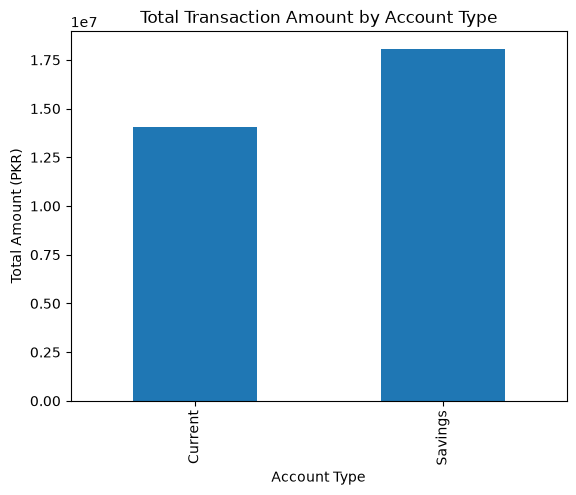

In [94]:
account_total.plot(kind="bar")

plt.title("Total Transaction Amount by Account Type")
plt.xlabel("Account Type")
plt.ylabel("Total Amount (PKR)")

plt.show()

In [95]:
transaction_total = df.groupby("TransactionType")["Amount"].sum()

transaction_total

TransactionType
Deposit        9862594
Transfer      10968252
Withdrawal    11296524
Name: Amount, dtype: int64

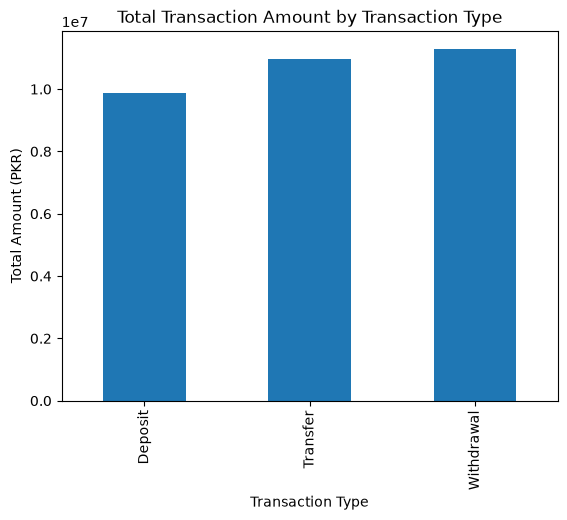

In [96]:
transaction_total.plot(kind="bar")

plt.title("Total Transaction Amount by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Total Amount (PKR)")

plt.show()

In [97]:
top_customers = df.groupby("CustomerID")["Amount"].sum().sort_values(ascending=False).head(10)

top_customers

CustomerID
C0039    1322677
C0044    1208828
C0024    1171110
C0015    1041383
C0027    1012050
C0028     979863
C0026     960765
C0060     948171
C0008     829683
C0051     819600
Name: Amount, dtype: int64

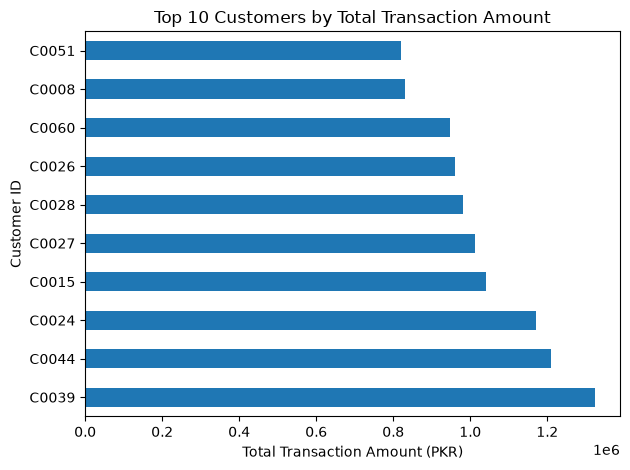

In [98]:
top_customers.plot(kind="barh")

plt.title("Top 10 Customers by Total Transaction Amount")
plt.xlabel("Total Transaction Amount (PKR)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [99]:
branch_transaction = df.groupby(["Branch", "TransactionType"])["Amount"].sum()

branch_transaction

Branch     TransactionType
Hyderabad  Deposit            1978472
           Transfer           2554743
           Withdrawal         3388260
Islamabad  Deposit            2340722
           Transfer           2681014
           Withdrawal         2407027
Karachi    Deposit            2176528
           Transfer           1614301
           Withdrawal         2403357
Lahore     Deposit            1957744
           Transfer           1125269
           Withdrawal          946831
Sukkur     Deposit            1409128
           Transfer           2992925
           Withdrawal         2151049
Name: Amount, dtype: int64

In [100]:
branch_transaction_table = branch_transaction.unstack()

branch_transaction_table

TransactionType,Deposit,Transfer,Withdrawal
Branch,,,
Hyderabad,1978472,2554743,3388260
Islamabad,2340722,2681014,2407027
Karachi,2176528,1614301,2403357
Lahore,1957744,1125269,946831
Sukkur,1409128,2992925,2151049


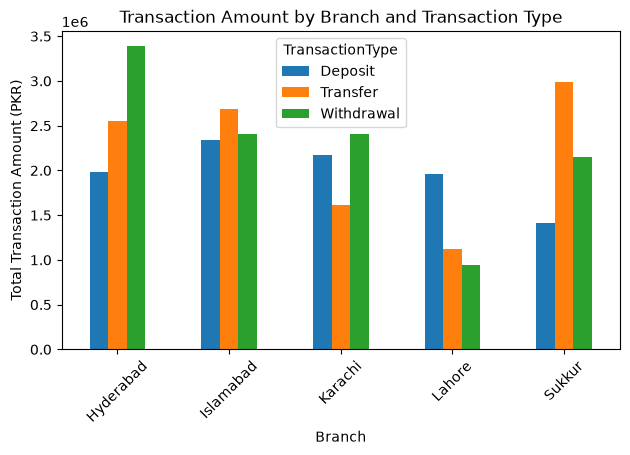

In [101]:
branch_transaction_table.plot(kind="bar")

plt.title("Transaction Amount by Branch and Transaction Type")
plt.xlabel("Branch")
plt.ylabel("Total Transaction Amount (PKR)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [102]:
high_value_transactions = df[df["Amount"] > 200000]

high_value_transactions

,TransactionID,CustomerID,Date,Branch,AccountType,TransactionType,Amount
7,T00008,C0039,2025-11-08,Karachi,Savings,Transfer,230703
9,T00010,C0019,2025-01-03,Hyderabad,Savings,Deposit,217023
12,T00013,C0011,2025-12-29,Hyderabad,Savings,Transfer,212451
13,T00014,C0024,2025-08-27,Hyderabad,Savings,Deposit,243511
21,T00022,C0002,2025-07-21,Islamabad,Savings,Transfer,238671
25,T00026,C0038,2025-03-27,Hyderabad,Current,Withdrawal,217638
26,T00027,C0002,2025-05-06,Islamabad,Current,Withdrawal,237072
28,T00029,C0021,2025-01-25,Sukkur,Current,Transfer,200476
36,T00037,C0027,2025-04-19,Islamabad,Savings,Withdrawal,233293
42,T00043,C0015,2025-04-21,Sukkur,Savings,Transfer,232948


In [103]:
len(high_value_transactions)

51

In [104]:
(high_value_transactions.shape[0] / df.shape[0]) * 100

20.4

In [105]:
branch_avg = (
    df.groupby("Branch")["Amount"]
    .mean()
    .sort_values(ascending=False)
)

branch_avg

Branch
Sukkur       136522.958333
Islamabad    135068.418182
Hyderabad    129860.245902
Karachi      126411.959184
Lahore       108914.702703
Name: Amount, dtype: float64

In [106]:
import json

dashboard_data = {
    "kpis": {
        "total_transactions": int(len(df)),
        "total_value": int(df["Amount"].sum()),
        "average_transaction": float(df["Amount"].mean())
    }
}

with open("../dashboard/public/dashboard_data.json", "w") as f:
    json.dump(dashboard_data, f, indent=4)

print("Dashboard data created successfully!")

Dashboard data created successfully!


In [107]:
branch_total = (
    df.groupby("Branch")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

dashboard_data["branch_performance"] = [
    {
        "branch": branch,
        "amount": int(amount)
    }
    for branch, amount in branch_total.items()
]

with open("../dashboard/public/dashboard_data.json", "w") as f:
    json.dump(dashboard_data, f, indent=4)

print("Branch data added successfully!")

Branch data added successfully!


In [108]:
transaction_type_total = (
    df.groupby("TransactionType")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

dashboard_data["transaction_type"] = [
    {
        "type": transaction_type,
        "amount": int(amount)
    }
    for transaction_type, amount in transaction_type_total.items()
]

with open("../dashboard/public/dashboard_data.json", "w") as f:
    json.dump(dashboard_data, f, indent=4)

print("Transaction type data added successfully!")

Transaction type data added successfully!


In [127]:
monthly_total = (
    df.groupby(df["Date"].dt.month)["Amount"]
    .sum()
    .sort_index()
)

dashboard_data["monthly_trend"] = [
    {
        "month": month,
        "amount": int(amount)
    }
    for month, amount in monthly_total.items()
]

with open("../dashboard/public/dashboard_data.json", "w") as f:
    json.dump(dashboard_data, f, indent=4)

print("Monthly trend data added successfully!")

Monthly trend data added successfully!


In [125]:
df["Date"] = pd.to_datetime(df["Date"])

In [126]:
print(df["Date"].dtype)

datetime64[us]


In [112]:
df.groupby("CustomerID")["Amount"].sum().nlargest(10)

CustomerID
C0039    1322677
C0044    1208828
C0024    1171110
C0015    1041383
C0027    1012050
C0028     979863
C0026     960765
C0060     948171
C0008     829683
C0051     819600
Name: Amount, dtype: int64

In [113]:
top_customers = (
    df.groupby("CustomerID")["Amount"]
    .sum()
    .nlargest(10)
)

print(top_customers)

CustomerID
C0039    1322677
C0044    1208828
C0024    1171110
C0015    1041383
C0027    1012050
C0028     979863
C0026     960765
C0060     948171
C0008     829683
C0051     819600
Name: Amount, dtype: int64


In [114]:
dashboard_data["top_customers"] = [
    {
        "customer": customer,
        "amount": int(amount)
    }
    for customer, amount in top_customers.items()
]


In [115]:
print(dashboard_data["top_customers"])

[{'customer': 'C0039', 'amount': 1322677}, {'customer': 'C0044', 'amount': 1208828}, {'customer': 'C0024', 'amount': 1171110}, {'customer': 'C0015', 'amount': 1041383}, {'customer': 'C0027', 'amount': 1012050}, {'customer': 'C0028', 'amount': 979863}, {'customer': 'C0026', 'amount': 960765}, {'customer': 'C0060', 'amount': 948171}, {'customer': 'C0008', 'amount': 829683}, {'customer': 'C0051', 'amount': 819600}]


In [116]:
with open("../dashboard/public/dashboard_data.json", "w") as f:
    json.dump(dashboard_data, f, indent=4)

print("Top customer data saved successfully!")

Top customer data saved successfully!


In [117]:
branch_total = df.groupby("Branch")["Amount"].sum()

top_branch = branch_total.idxmax()
top_branch_value = int(branch_total.max())

print(top_branch)
print(top_branch_value)

Hyderabad
7921475


In [118]:
monthly_total = df.groupby(df["Date"].dt.month)["Amount"].sum()

top_month_number = monthly_total.idxmax()
top_month_value = int(monthly_total.max())

import calendar

top_month_name = calendar.month_name[top_month_number]

print(top_month_name)
print(top_month_value)

November
4003414


In [119]:
branch_average = df.groupby("Branch")["Amount"].mean()

top_average_branch = branch_average.idxmax()
top_average_value = round(branch_average.max(), 2)

print(top_average_branch)
print(top_average_value)

Sukkur
136522.96


In [120]:
high_value_count = int((df["Amount"] > 200000).sum())
total_transactions = len(df)

high_value_percentage = round(
    (high_value_count / total_transactions) * 100,
    1
)

print(high_value_count)
print(high_value_percentage)

51
20.4


In [121]:
dashboard_data["insights"] = [
    {
        "title": "Leading Branch",
        "value": top_branch,
        "description": (
            f"Highest total transaction value: "
            f"PKR {top_branch_value:,}"
        ),
    },
    {
        "title": "Monthly Peak",
        "value": top_month_name,
        "description": (
            f"Highest monthly transaction value: "
            f"PKR {top_month_value:,}"
        ),
    },
    {
        "title": "Highest Average Transaction",
        "value": top_average_branch,
        "description": (
            f"Average transaction amount: "
            f"PKR {top_average_value:,.2f}"
        ),
    },
    {
        "title": "High-Value Transactions",
        "value": f"{high_value_percentage}%",
        "description": (
            f"{high_value_count} of {total_transactions} "
            f"transactions exceeded PKR 200,000"
        ),
    },
]

print(dashboard_data["insights"])

[{'title': 'Leading Branch', 'value': 'Hyderabad', 'description': 'Highest total transaction value: PKR 7,921,475'}, {'title': 'Monthly Peak', 'value': 'November', 'description': 'Highest monthly transaction value: PKR 4,003,414'}, {'title': 'Highest Average Transaction', 'value': 'Sukkur', 'description': 'Average transaction amount: PKR 136,522.96'}, {'title': 'High-Value Transactions', 'value': '20.4%', 'description': '51 of 250 transactions exceeded PKR 200,000'}]


In [122]:
with open("../dashboard/public/dashboard_data.json", "w") as f:
    json.dump(dashboard_data, f, indent=4)

print("Dynamic insights saved successfully!")

Dynamic insights saved successfully!


In [123]:

account_type_total = (
    df.groupby("AccountType")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

dashboard_data["account_type"] = [
    {"account": account, "amount": int(amount)}
    for account, amount in account_type_total.items()
]

with open("../dashboard/public/dashboard_data.json", "w") as f:
    json.dump(dashboard_data, f, indent=4)

print(dashboard_data["account_type"])


[{'account': 'Savings', 'amount': 18067812}, {'account': 'Current', 'amount': 14059558}]


In [124]:
dashboard_data["transactions"] = [
    {
        "transaction_id": str(row["TransactionID"]),
        "customer": str(row["CustomerID"]),
        "month": int(row["Date"].month),
        "branch": str(row["Branch"]),
        "account": str(row["AccountType"]),
        "type": str(row["TransactionType"]),
        "amount": int(row["Amount"]),
    }
    for _, row in df.iterrows()
]

with open("../dashboard/public/dashboard_data.json", "w") as f:
    json.dump(dashboard_data, f, indent=4)

print("Transactions added:", len(dashboard_data["transactions"]))

Transactions added: 250
